<div dir="rtl">

# مشروع صغير: تحليل طلبات مطعم بمساعدة الذكاء الاصطناعي

**السؤال الرئيسي:** أين تربح إدارة المطعم، ومتى يزدحم، وما الذي يُغضب العملاء؟

**البيانات:** `restaurant_orders.csv` (طلبات 3 فروع، يناير إلى يونيو 2025). اقرأ `data_dictionary_restaurant.md` أولًا.

**المهارات المستخدمة في Cursor:** `/data-quality-report` ← `/kpi-summary` ← `/clear-charts` ← `/insight-report`

**طريقة العمل:** لكل سؤال: اطلب من Agent الكود (أو استدعِ المهارة)، اقرأ الكود قبل قبوله، شغّله، ثم قارن بنقطة التحقق.

</div>


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
# ملاحظة: استخدم pandas وmatplotlib فقط في هذا الدفتر.

df = pd.read_csv("restaurant_orders.csv")
print(df.shape)   # نقطة تحقق: (1515, 12)
df.head()

(1515, 12)


,order_id,order_date,order_hour,branch,channel,category,item,quantity,unit_price,total,delivery_minutes,rating
0,R10001,2025-01-01,11,Downtown,Delivery,Sides,Hummus,5,3.5,17.5,43.0,3.0
1,R10002,2025-01-01,19,Mall,Takeaway,Main,Falafel Wrap,4,4.5,18.0,NaN,4.0
2,R10003,2025-01-01,20,Downtown,Dine-in,Main,Chicken Shawarma,3,6.5,19.5,NaN,NaN
3,R10004,2025-01-01,22,University,Delivery,Main,Beef Burger,2,8.0,16.0,28.0,5.0
4,R10005,2025-01-02,11,Mall,Delivery,Drinks,Fresh Juice,3,3.0,9.0,29.0,4.0


<div dir="rtl">

## الخطوة 1: فحص الجودة والتنظيف

شغّل الخلية التالية لإنتاج تقرير الجودة. راجع النتائج قبل تنظيف البيانات، ولا تعدّل الملف الأصلي.

**نقطة تحقق:** 15 صفًا مكررًا، و6 صيغ غير موحدة إضافية لأسماء الفروع، و136 تقييمًا مفقودًا. بعد التنظيف: **1500 صف** و3 فروع فقط.

</div>


In [3]:
# تقرير جودة البيانات: الفحص فقط، دون تعديل البيانات الأصلية.
print("حجم البيانات:", df.shape)
print("\nأنواع الأعمدة:")
print(df.dtypes)

print("\nالقيم المفقودة في كل عمود:")
print(df.isna().sum())

print("\nعدد الصفوف المكررة بالكامل:", df.duplicated().sum())

print("\nالقيم المختلفة في الأعمدة النصية ذات أقل من 20 قيمة:")
for column in df.select_dtypes(include=["object", "string"]).columns:
    values = df[column].dropna().unique()
    if len(values) < 20:
        print(f"{column} ({len(values)} قيمة): {values.tolist()}")

print("\nنطاقات الأعمدة الرقمية والقيم السالبة:")
for column in df.select_dtypes(include="number").columns:
    values = df[column].dropna()
    print(
        f"{column}: أصغر قيمة={values.min()}, أكبر قيمة={values.max()}, "
        f"عدد القيم السالبة={(values < 0).sum()}"
    )

# نميّز القيم الفارغة المتوقعة للتوصيل عن القيم المفقودة في طلبات التوصيل.
missing_ratings = int(df["rating"].isna().sum())
duplicate_rows = int(df.duplicated().sum())
branch_normalized = df["branch"].str.strip().str.title()
branch_rows_to_normalize = int((df["branch"] != branch_normalized).sum())
missing_delivery_times = int(
    df.loc[df["channel"].eq("Delivery"), "delivery_minutes"].isna().sum()
)

issues = [
    {
        "المشكلة": "تقييمات مفقودة",
        "العمود": "rating",
        "عدد الصفوف": missing_ratings,
        "اقتراح المعالجة": "أبقِ الصفوف واستبعد التقييمات المفقودة عند حساب المتوسط.",
    },
    {
        "المشكلة": "صفوف مكررة بالكامل",
        "العمود": "جميع الأعمدة",
        "عدد الصفوف": duplicate_rows,
        "اقتراح المعالجة": "راجع التكرارات، ثم احذفها من نسخة التحليل إذا تأكدت.",
    },
    {
        "المشكلة": "مسافات أو اختلاف في حالة الأحرف باسم الفرع",
        "العمود": "branch",
        "عدد الصفوف": branch_rows_to_normalize,
        "اقتراح المعالجة": "وحّد المسافات وحالة الأحرف في نسخة التحليل بعد المراجعة.",
    },
]

if missing_delivery_times:
    issues.append(
        {
            "المشكلة": "أوقات توصيل مفقودة لطلبات التوصيل",
            "العمود": "delivery_minutes",
            "عدد الصفوف": missing_delivery_times,
            "اقتراح المعالجة": "تحقق من مصدر البيانات لهذه الطلبات قبل التحليل.",
        }
    )

print("\nتقرير المشكلات والاقتراحات:")
display(pd.DataFrame(issues))
print("القيم الفارغة في delivery_minutes لطلبات غير التوصيل متوقعة.")


حجم البيانات: (1515, 12)

أنواع الأعمدة:
order_id                str
order_date              str
order_hour            int64
branch                  str
channel                 str
category                str
item                    str
quantity              int64
unit_price          float64
total               float64
delivery_minutes    float64
rating              float64
dtype: object

القيم المفقودة في كل عمود:
order_id               0
order_date             0
order_hour             0
branch                 0
channel                0
category               0
item                   0
quantity               0
unit_price             0
total                  0
delivery_minutes    1137
rating               136
dtype: int64

عدد الصفوف المكررة بالكامل: 15

القيم المختلفة في الأعمدة النصية ذات أقل من 20 قيمة:
branch (9 قيمة): ['Downtown', 'Mall', 'University', ' mall', ' university', 'MALL', 'DOWNTOWN', ' downtown', 'UNIVERSITY']
channel (3 قيمة): ['Delivery', 'Takeaway', 'Dine-in']
categ

,المشكلة,العمود,عدد الصفوف,اقتراح المعالجة
0,تقييمات مفقودة,rating,136,أبقِ الصفوف واستبعد التقييمات المفقودة عند حسا...
1,صفوف مكررة بالكامل,جميع الأعمدة,15,راجع التكرارات، ثم احذفها من نسخة التحليل إذا ...
2,مسافات أو اختلاف في حالة الأحرف باسم الفرع,branch,24,وحّد المسافات وحالة الأحرف في نسخة التحليل بعد...


القيم الفارغة في delivery_minutes لطلبات غير التوصيل متوقعة.


In [7]:
# ننظّف نسخة التحليل فقط ونحافظ على df والملف الأصلي كما هما.
clean = df.drop_duplicates().copy()
clean["branch"] = clean["branch"].str.strip().str.title()

print("حجم البيانات بعد التنظيف:", clean.shape)
print("عدد الفروع بعد توحيد الأسماء:", clean["branch"].nunique())
print("أسماء الفروع:", sorted(clean["branch"].unique()))
print("عدد التقييمات المفقودة (نحتفظ بصفوفها):", clean["rating"].isna().sum())


حجم البيانات بعد التنظيف: (1500, 12)
عدد الفروع بعد توحيد الأسماء: 3
أسماء الفروع: ['Downtown', 'Mall', 'University']
عدد التقييمات المفقودة (نحتفظ بصفوفها): 132


<div dir="rtl">

## الخطوة 2: مؤشرات الأداء (س1)

**س1:** ما إجمالي الإيرادات وعدد الطلبات ومتوسط قيمة الطلب ومتوسط التقييم؟ وما هي لكل فرع؟

شغّل الخلية التالية لحساب المؤشرات العامة ومقارنتها بين الفروع.

</div>


In [2]:
# المؤشرات العامة: عدد الطلبات هو عدد أرقام الطلبات المختلفة.
total_revenue = clean["total"].sum()
total_orders = clean["order_id"].nunique()
average_order_value = total_revenue / total_orders
average_rating = clean["rating"].mean()

overall_kpis = pd.DataFrame(
    {
        "المؤشر": ["إجمالي الإيرادات ($)",
                   "عدد الطلبات",
                   "متوسط قيمة الطلب ($)",
                   "متوسط التقييم"],
        "القيمة": [total_revenue,
                   total_orders,
                   average_order_value,
                   average_rating],
    }
)
display(overall_kpis.round(2))

# مقارنة الفروع وترتيبها حسب الإيرادات.
branch_kpis = (
    clean.groupby("branch")
    .agg(
        revenue=("total", "sum"),
        orders=("order_id", "nunique"),
        average_rating=("rating", "mean"),
    )
    .sort_values("revenue", ascending=False)
)
branch_kpis["average_order_value"] = branch_kpis["revenue"] / branch_kpis["orders"]
branch_kpis["revenue_share_percent"] = branch_kpis["revenue"] / total_revenue * 100
branch_kpis = branch_kpis.round(2)
display(branch_kpis)

assert round(branch_kpis["revenue"].sum(), 2) == round(total_revenue, 2) 
print("تحقق: مجموع إيرادات الفروع يساوي إجمالي الإيرادات:", round(total_revenue, 2))
print(f"أعلى فرع إيرادًا: {branch_kpis.index[0]} — ${branch_kpis.iloc[0]['revenue']:.2f}.")
print(f"أقل فرع إيرادًا: {branch_kpis.index[-1]} — ${branch_kpis.iloc[-1]['revenue']:.2f}.")
print(f"الفرق بينهما: ${branch_kpis.iloc[0]['revenue'] - branch_kpis.iloc[-1]['revenue']:.2f}.")


NameError: name 'clean' is not defined

<div dir="rtl">

## الخطوة 3: الذروة والقنوات والأصناف (س2، س3، س4)

- **س2:** ما ساعات الذروة؟ وأي أيام الأسبوع أكثر ازدحامًا؟
- **س3:** ما حصة كل قناة (صالة، سفري، توصيل) من الإيرادات؟
- **س4:** ما أعلى 5 أصناف من حيث الإيرادات؟

شغّل الخليتين التاليتين لعرض الذروة، ومقارنة القنوات، وأعلى الأصناف.

</div>


عدد الطلبات حسب الساعة:


,orders
order_hour,
10,17
11,47
12,110
13,216
14,153
15,75
16,49
17,67
18,94


عدد الطلبات حسب يوم الأسبوع (مرتبة من الأكثر ازدحامًا):


,orders,revenue
Saturday,280,3561.5
Friday,278,3784.5
Monday,204,2388.0
Thursday,197,2485.0
Sunday,182,2227.5
Wednesday,180,2163.5
Tuesday,179,2141.0


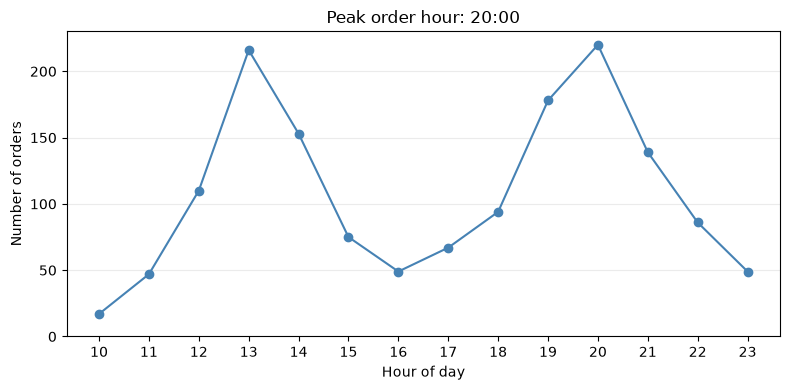

الأرقام المرسومة — الطلبات حسب الساعة:


,orders
order_hour,
10,17
11,47
12,110
13,216
14,153
15,75
16,49
17,67
18,94


In [9]:
# أعداد الطلبات حسب الساعة ويوم الأسبوع.

hourly_orders = clean.groupby("order_hour")["order_id"].nunique().reindex(range(10, 24), fill_value=0)
weekday_orders = clean.assign(
    weekday_number=pd.to_datetime(clean["order_date"]).dt.dayofweek
).groupby("weekday_number").agg(
    orders=("order_id", "nunique"),
    revenue=("total", "sum"),
)
weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_orders.index = [weekday_names[index] for index in weekday_orders.index]
weekday_orders = weekday_orders.sort_values("orders", ascending=False)

print("عدد الطلبات حسب الساعة:")
display(hourly_orders.rename("orders").to_frame())
print("عدد الطلبات حسب يوم الأسبوع (مرتبة من الأكثر ازدحامًا):")
display(weekday_orders)

peak_hour = int(hourly_orders.idxmax())
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hourly_orders.index, hourly_orders.values, marker="o", color="steelblue")
ax.set_title(f"Peak order hour: {peak_hour}:00")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Number of orders")
ax.set_xticks(hourly_orders.index)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
print("الأرقام المرسومة — الطلبات حسب الساعة:")
display(hourly_orders.rename("orders").to_frame())


,revenue,revenue_share_percent
channel,,
Dine-in,8122.0,43.32
Takeaway,5459.0,29.11
Delivery,5170.0,27.57


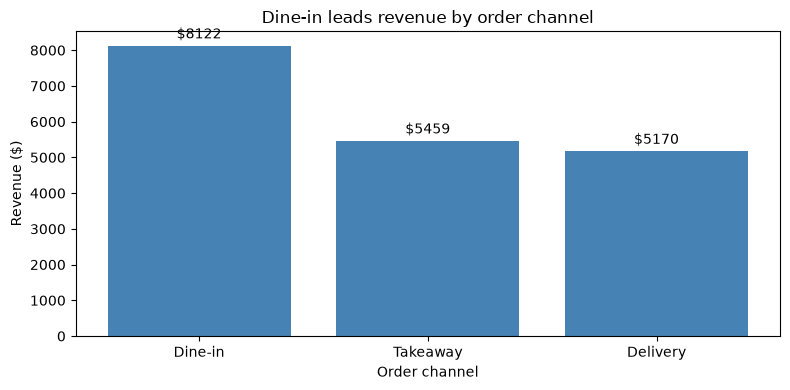

الأرقام المرسومة — الإيرادات حسب القناة:


,revenue,revenue_share_percent
channel,,
Dine-in,8122.0,43.32
Takeaway,5459.0,29.11
Delivery,5170.0,27.57


أعلى خمسة أصناف من حيث الإيرادات:


,revenue,quantity
item,,
Mixed Grill,4864.0,304
Grilled Chicken Plate,3399.0,309
Beef Burger,2464.0,308
Chicken Shawarma,1878.5,289
Falafel Wrap,1314.0,292


In [12]:
# مقارنة الإيرادات حسب قناة الطلب، ثم عرض أعلى خمسة أصناف.
channel_revenue = (
    clean.groupby("channel")["total"]
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="revenue")
)
channel_revenue["revenue_share_percent"] = channel_revenue["revenue"] / total_revenue * 100
channel_revenue = channel_revenue.round(2)
display(channel_revenue)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(channel_revenue.index, channel_revenue["revenue"], color="steelblue")
ax.set_title(f"{channel_revenue.index[0]} leads revenue by order channel")
ax.set_xlabel("Order channel")
ax.set_ylabel("Revenue ($)")
ax.set_ylim(bottom=0)
ax.bar_label(bars, fmt="$%.0f", padding=3)
plt.tight_layout()
plt.show()
print("الأرقام المرسومة — الإيرادات حسب القناة:")
display(channel_revenue)

top_items = (
    clean.groupby("item")
    .agg(revenue=("total", "sum"), quantity=("quantity", "sum"))
    .sort_values("revenue", ascending=False)
    .head(5)
    .round(2)
)
print("أعلى خمسة أصناف من حيث الإيرادات:")
display(top_items)


<div dir="rtl">

## الخطوة 4: رضا العملاء (س5)

**س5:** هل يرتبط وقت التوصيل بتقييم العميل؟
قسّم طلبات التوصيل إلى ثلاث فئات: أقل من 30 دقيقة، من 30 إلى 45، أكثر من 45. ثم احسب عدد الطلبات ومتوسط التقييم لكل فئة.

> هذه مقارنة بين متوسطات، لا تحتاج أي نموذج تعلم آلي. لكنها لا تثبت السبب وحدها.

</div>


In [26]:
# نقارن عدد الطلبات ومتوسط التقييم لكل فئة من أوقات التوصيل.

delivery_orders = clean.loc[clean["channel"].eq("Delivery")].copy()
delivery_orders["delivery_group"] = pd.NA

delivery_orders.loc[
delivery_orders["delivery_minutes"] < 30,
"delivery_group"
] = "Under 30 min"

delivery_orders.loc[
delivery_orders["delivery_minutes"].between(
30, 45, inclusive="both"
),
"delivery_group"
] = "30-45 min"

delivery_orders.loc[
delivery_orders["delivery_minutes"] > 45,
"delivery_group"
] = "Over 45 min"

delivery_orders["delivery_group"] = pd.Categorical(
delivery_orders["delivery_group"],
categories=[
"Under 30 min",
"30-45 min",
"Over 45 min"
],
ordered=True
)

delivery_summary = (
delivery_orders.groupby(
"delivery_group",
observed=False
)
.agg(
orders=("order_id", "nunique"),
rated_orders=("rating", "count"),
average_rating=("rating", "mean"),
average_delivery_minutes=(
"delivery_minutes", "mean"
),
)
.round(2)
)

display(delivery_summary)
print("التقييمات المفقودة مستبعدة تلقائيًا من متوسط التقييم، مع إبقاء الطلبات ضمن العدد.")


,orders,rated_orders,average_rating,average_delivery_minutes
delivery_group,,,,
Under 30 min,69,61,4.11,22.52
30-45 min,200,185,3.59,38.01
Over 45 min,105,94,2.47,52.67


التقييمات المفقودة مستبعدة تلقائيًا من متوسط التقييم، مع إبقاء الطلبات ضمن العدد.


<div dir="rtl">

## الخطوة 5: الرؤى والتوصيات (س6)

### ثلاث رؤى

1. **فرع Mall يحقق أعلى إيراد**: سجّل **$7,933** مقابل **$4,140** لفرع University، وفق جدول مؤشرات الفروع في الخطوة 2.
2. **الساعة 20 هي الأكثر ازدحامًا**: سُجّل فيها **220 طلبًا**، وفق جدول الطلبات حسب الساعة في الخطوة 3.
3. **يرتبط وقت التوصيل الأطول بمتوسط تقييم أقل في هذه البيانات**: المتوسط **4.11** لمن استلموا خلال أقل من 30 دقيقة، و**2.47** لمن تجاوز توصيلهم 45 دقيقة، وفق جدول الخطوة 4. هذا ارتباط وصفي وليس إثباتًا للسببية.

### ثلاث توصيات

1. **راجع تجربة فرع University** وقارن إيراده البالغ **$4,140** بإيراد Mall البالغ **$7,933**؛ وتابع الإيراد وعدد الطلبات لكل فرع شهريًا لقياس التحسن.
2. **خطط لتغطية فترة الذروة حول الساعة 20:00** التي شهدت **220 طلبًا**؛ وقِس عدد الطلبات وزمن الانتظار في هذه الساعة بعد تعديل الجدولة.
3. **تابع الطلبات التي يتجاوز توصيلها 45 دقيقة**؛ كان متوسط تقييمها **2.47** مقابل **4.11** للأقل من 30 دقيقة. قِس نسبة الطلبات التي تتجاوز 45 دقيقة ومتوسط تقييم التوصيل دوريًا.

### ما لا نعرفه بعد

لا توضح البيانات تكاليف التشغيل أو هوامش الربح، لذلك لا يمكن تحديد الفرع الأكثر ربحية من الإيرادات وحدها.
ولا تثبت المقارنة أن طول التوصيل هو سبب انخفاض التقييم؛ كما أن البيانات تغطي الفترة من يناير إلى يونيو 2025 فقط.

راجع الأرقام في مخرجات الخطوات 2 و3 و4 قبل اعتماد الرؤى والتوصيات.

## سجل التحقق

| ماذا قال الذكاء الاصطناعي | كيف تحققت | النتيجة |
| ------------------------- | --------- | ------- |
|                           |           |         |

</div>


In [27]:
print(
    "الطلبات التي استغرقت 30 دقيقة:",
    (delivery_orders["delivery_minutes"] == 30).sum()
)

print(
    "الطلبات التي استغرقت 45 دقيقة:",
    (delivery_orders["delivery_minutes"] == 45).sum()
)

print("\nعدد الطلبات في كل فئة:")
print(delivery_orders["delivery_group"].value_counts())

الطلبات التي استغرقت 30 دقيقة: 17
الطلبات التي استغرقت 45 دقيقة: 13

عدد الطلبات في كل فئة:
delivery_group
30-45 min       200
Over 45 min     105
Under 30 min     69
Name: count, dtype: int64


In [22]:
print(
    delivery_orders.loc[
        delivery_orders["delivery_minutes"].isin([30, 45]),
        ["delivery_minutes", "delivery_group"]
    ].value_counts().sort_index()
)

delivery_minutes  delivery_group
30.0              Under 30 min       0
                  30-45 min         17
                  Over 45 min        0
45.0              Under 30 min       0
                  30-45 min         13
                  Over 45 min        0
Name: count, dtype: int64


In [28]:
branch_summary = (
    clean.groupby("branch")
    .agg(revenue=("total", "sum"), orders=("order_id", "nunique"))
)
branch_summary["average_order_value"] = branch_summary["revenue"] / branch_summary["orders"]
branch_summary["revenue_share_percent"] = branch_summary["revenue"] / clean["total"].sum() * 100
branch_summary = branch_summary.sort_values("revenue", ascending=False).round(2)
branch_summary = branch_summary.rename(columns={
    "revenue": "الإيرادات ($)",
    "orders": "عدد الطلبات",
    "average_order_value": "متوسط قيمة الطلب ($)",
    "revenue_share_percent": "النسبة من الإجمالي %",
})
display(branch_summary)

total_revenue = clean["total"].sum()
assert round(branch_summary["الإيرادات ($)"].sum(), 2) == round(total_revenue, 2)
print(f"أعلى فرع إيرادًا: {branch_summary.index[0]} — ${branch_summary.iloc[0]['الإيرادات ($)']:.2f}.")
print(f"أقل فرع إيرادًا: {branch_summary.index[-1]} — ${branch_summary.iloc[-1]['الإيرادات ($)']:.2f}.")
print(f"الفرق بينهما: ${branch_summary.iloc[0]['الإيرادات ($)'] - branch_summary.iloc[-1]['الإيرادات ($)']:.2f}.")

,الإيرادات ($),عدد الطلبات,متوسط قيمة الطلب ($),النسبة من الإجمالي %
branch,,,,
Mall,7933.0,590,13.45,42.31
Downtown,6678.0,466,14.33,35.61
University,4140.0,444,9.32,22.08


أعلى فرع إيرادًا: Mall — $7933.00.
أقل فرع إيرادًا: University — $4140.00.
الفرق بينهما: $3793.00.
